  ### **Multi-Modal Spatio-Temporal Air Quality Forecasting, Health-Risk Stratification, and Unsupervised Pollution Regime Discovery Across Diverse Indian Urban Climates Using Ensemble Machine Learning**

### Problem Statement
Indian metropolitan cities exhibit drastically different atmospheric pollution behaviors depending on geography (coastal vs. inland vs. Indo-Gangetic basin) and meteorology (monsoon washout vs. winter thermal inversion). Standard single-city AQI monitors only report current pollution levels without explaining meteorological drivers, health-risk probabilities, or recurring pollution regimes. This project builds a unified, multi-task Machine Learning pipeline that:
1. **Predicts continuous US AQI** from chemical pollutants and weather variables (Regression).
2. **Classifies hourly conditions** into Binary Health Risk (Safe/Moderate vs. Unhealthy) and 3-Tier Severity Levels (Classification & Ensembles).
3. **Discovers latent Pollution Regimes** (e.g., Winter Particulate Smog vs. Summer Photochemical Ozone) and extreme anomaly spikes without labels (Unsupervised Learning).

### Environment Setup, Drive Mounting, and Data Loading
This block configures the runtime environment, installs required packages, and mounts Google Drive. It then loads the raw multi-city meteorological and chemical pollution dataset to prepare it for subsequent preprocessing.

In [1]:
# Setup Environment, Mount Drive & Load Dataset
!pip install -q "numpy<2.4" ydata-profiling

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from google.colab import drive

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    LabelEncoder,
    OneHotEncoder,
    Binarizer,
    KBinsDiscretizer
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")

# 1. Mount Google Drive
drive.mount('/content/drive')

# Set project directory
PROJECT_DIR = '/content/drive/MyDrive/Mini Project/dataset'
os.makedirs(PROJECT_DIR, exist_ok=True)

INPUT_PATH = os.path.join(PROJECT_DIR, 'india_1yr_air_quality_full_2026.csv')
# Fallback if uploaded directly to Colab session storage (/content/)
if not os.path.exists(INPUT_PATH):
    INPUT_PATH = 'india_1yr_air_quality_full_2026.csv'

df = pd.read_csv(INPUT_PATH)
print(f"Loaded dataset successfully: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(3)

Mounted at /content/drive
Loaded dataset successfully: 52,704 rows x 31 columns


,city,region_zone,latitude,longitude,time,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,...,wind_speed_10m,wind_direction_10m,shortwave_radiation,month,hour,day_of_week,is_weekend,season,high_health_risk,health_risk_level
0,Pune,West_Deccan,18.5204,73.8567,2025-11-10 00:00:00,44.9,44.8,964.0,37.1,23.4,...,5.4,255,0.0,11,0,0,0,Post_Monsoon,0,0
1,Pune,West_Deccan,18.5204,73.8567,2025-11-10 01:00:00,49.2,49.1,741.0,37.1,23.7,...,3.8,259,0.0,11,1,0,0,Post_Monsoon,0,0
2,Pune,West_Deccan,18.5204,73.8567,2025-11-10 02:00:00,52.5,52.4,562.0,36.4,23.9,...,1.1,189,0.0,11,2,0,0,Post_Monsoon,0,0


=== OUTLIER DETECTION SUMMARY (Z-SCORE vs. IQR) ===


,Mean,Median,Skewness,Z_Score_Outliers (>3σ),Z_Outlier_%,IQR_Outliers (1.5x),IQR_Outlier_%,IQR_Lower,IQR_Upper
dust,55.03,6.00,5.80,1405,2.67,6878,13.05,-25.00,47.00
pm10,68.56,37.80,5.10,1384,2.63,5412,10.27,-35.81,119.89
nitrogen_dioxide,16.87,11.60,2.47,1183,2.24,3520,6.68,-16.20,43.80
carbon_monoxide,452.03,345.00,3.25,1163,2.21,3555,6.75,-210.50,977.50
pm2_5,38.97,28.40,2.31,1066,2.02,2997,5.69,-36.25,102.55
sulphur_dioxide,16.24,11.70,2.08,827,1.57,2024,3.84,-17.70,46.30
precipitation,0.12,0.00,14.11,757,1.44,8707,16.52,0.00,0.00
aerosol_optical_depth,0.46,0.41,1.49,746,1.42,1667,3.16,-0.16,1.04
ozone,90.86,79.00,1.67,684,1.30,1083,2.05,-48.50,219.50
uv_index,1.73,0.00,1.60,682,1.29,4586,8.70,-4.05,6.75


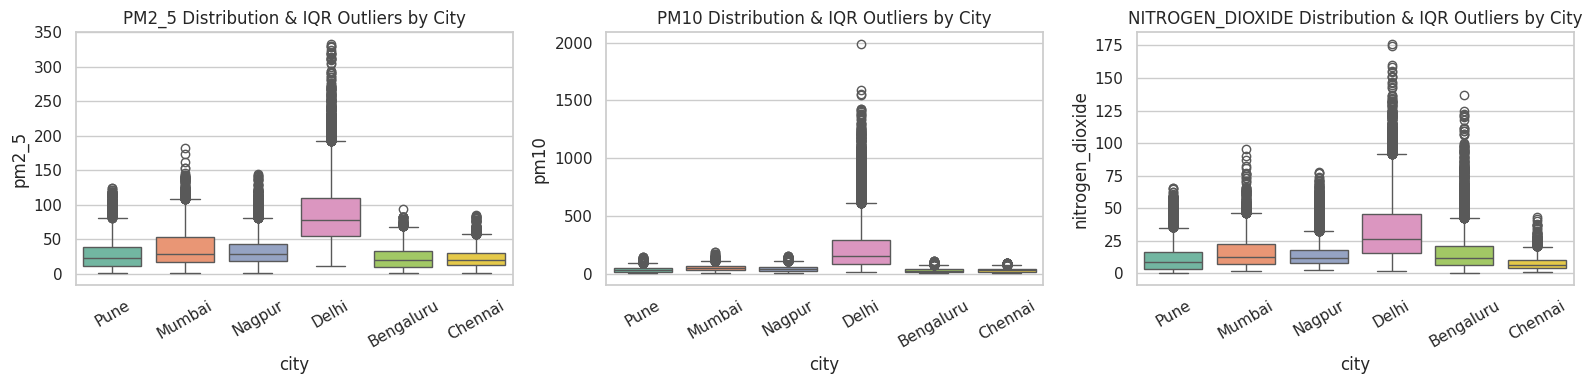

In [2]:
# Outlier Detection using Z-Score (|Z| > 3) & IQR (1.5 * IQR)
numeric_cols = [
    'pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide',
    'ozone', 'aerosol_optical_depth', 'dust', 'uv_index',
    'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'precipitation',
    'surface_pressure', 'cloud_cover', 'wind_speed_10m', 'wind_direction_10m',
    'shortwave_radiation'
]

# 1. Z-Score Method (Parametric: assumes Gaussian distribution, threshold |Z| > 3)
z_scores = np.abs(stats.zscore(df[numeric_cols]))
z_outlier_counts = (z_scores > 3).sum(axis=0)

# 2. Interquartile Range (IQR) Method (Non-parametric: robust to skewed data)
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
iqr_outlier_counts = ((df[numeric_cols] < lower_bound) | (df[numeric_cols] > upper_bound)).sum()

# Summary Comparison Table
outlier_summary = pd.DataFrame({
    'Mean': df[numeric_cols].mean().round(2),
    'Median': df[numeric_cols].median().round(2),
    'Skewness': df[numeric_cols].skew().round(2),
    'Z_Score_Outliers (>3σ)': z_outlier_counts,
    'Z_Outlier_%': (z_outlier_counts / len(df) * 100).round(2),
    'IQR_Outliers (1.5x)': iqr_outlier_counts,
    'IQR_Outlier_%': (iqr_outlier_counts / len(df) * 100).round(2),
    'IQR_Lower': lower_bound.round(2),
    'IQR_Upper': upper_bound.round(2)
}).sort_values(by='Z_Score_Outliers (>3σ)', ascending=False)

print("=== OUTLIER DETECTION SUMMARY (Z-SCORE vs. IQR) ===")
display(outlier_summary)

# Add row-level outlier flag columns for downstream anomaly validation (Unit 6 DBSCAN)
df_fe = df.copy()
df_fe['is_zscore_outlier_pm25'] = (np.abs(stats.zscore(df_fe['pm2_5'])) > 3).astype(int)
df_fe['is_iqr_outlier_pm25'] = (
    (df_fe['pm2_5'] < lower_bound['pm2_5']) | (df_fe['pm2_5'] > upper_bound['pm2_5'])
).astype(int)

# Boxplot Visualization of Top Skewed Pollutants
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['pm2_5', 'pm10', 'nitrogen_dioxide']):
    sns.boxplot(data=df_fe, x='city', y=col, ax=ax, palette='Set2')
    ax.set_title(f'{col.upper()} Distribution & IQR Outliers by City')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

### Domain-Driven and Cyclical Feature Engineering
Here, we extract advanced meteorological variables such as particulate ratios, stagnation indices, and dew-point depression based on physical domain knowledge. It also applies sine and cosine mathematical transformations to temporal components to correctly preserve cyclical continuity in hours and months.

In [3]:
# Domain-Driven & Cyclical Feature Extraction
# 1. Fine-to-Coarse Particulate Ratio (High ratio > 0.6 = vehicular/biomass combustion; Low = coarse windblown dust)
df_fe['pm_ratio'] = df_fe['pm2_5'] / (df_fe['pm10'] + 1e-5)

# 2. Dew Point Depression (T - Td: measures atmospheric dryness & thermal inversion potential)
df_fe['dew_point_depression'] = df_fe['temperature_2m'] - df_fe['dew_point_2m']

# 3. Atmospheric Stagnation Index (High surface pressure + low wind speed traps pollutants near ground)
df_fe['stagnation_index'] = df_fe['surface_pressure'] / (df_fe['wind_speed_10m'] + 1.0)

# 4. Photochemical Smog Potential (NO2 precursor * Solar Radiation drives ground-level Ozone)
df_fe['photochemical_index'] = (df_fe['nitrogen_dioxide'] * df_fe['shortwave_radiation']) / 1000.0

# 5. Cyclical Temporal Encodings (Preserves circular continuity: 23:00 is close to 00:00, Dec is close to Jan)
df_fe['hour_sin'] = np.sin(2 * np.pi * df_fe['hour'] / 24.0)
df_fe['hour_cos'] = np.cos(2 * np.pi * df_fe['hour'] / 24.0)
df_fe['month_sin'] = np.sin(2 * np.pi * df_fe['month'] / 12.0)
df_fe['month_cos'] = np.cos(2 * np.pi * df_fe['month'] / 12.0)

# 6. Urban Traffic Rush-Hour Flag (8-10 AM & 6-9 PM)
df_fe['is_rush_hour'] = df_fe['hour'].isin([8, 9, 10, 18, 19, 20, 21]).astype(int)

extracted_cols = [
    'pm_ratio', 'dew_point_depression', 'stagnation_index', 'photochemical_index',
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'is_rush_hour'
]
print("Extracted 9 new features successfully:")
display(df_fe[extracted_cols].describe().round(3))

Extracted 9 new features successfully:


,pm_ratio,dew_point_depression,stagnation_index,photochemical_index,hour_sin,hour_cos,month_sin,month_cos,is_rush_hour
count,52704.000,52704.000,52704.000,52704.000,52704.000,52704.000,52704.000,52704.000,52704.000
mean,0.751,9.322,125.893,2.043,-0.000,-0.000,-0.007,-0.000,0.292
std,0.222,7.466,90.635,3.654,0.707,0.707,0.705,0.709,0.455
min,0.101,-0.100,26.874,0.000,-1.000,-1.000,-1.000,-1.000,0.000
25%,0.611,3.500,72.869,0.000,-0.707,-0.707,-0.866,-0.866,0.000
50%,0.806,7.200,98.318,0.139,0.000,-0.000,-0.000,-0.000,0.000
75%,0.950,13.100,145.646,2.810,0.707,0.707,0.500,0.866,1.000
max,1.000,42.600,1010.700,44.141,1.000,1.000,1.000,1.000,1.000


### Discretization Binning and Target Binarization
This cell discretizes continuous values into domain-specific bins (such as thermal comfort categories) and maps equal-frequency intervals. It also binarizes environmental features to establish precise warning thresholds based on official safety standards.

In [4]:
# Binning (Discretization) & Binarization

# --- A. BINNING (DISCRETIZATION) ---
# 1. Domain-based Temperature Thermal Comfort Bins
df_fe['temp_bin'] = pd.cut(
    df_fe['temperature_2m'],
    bins=[-10, 18, 28, 35, 60],
    labels=['Cool', 'Pleasant', 'Warm', 'Extreme_Heat']
)

# 2. Quantile-based Equal-Frequency Binning for PM2.5 (4 quartiles: 0, 1, 2, 3)
kbd_pm25 = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')
df_fe['pm25_quantile_bin'] = kbd_pm25.fit_transform(df_fe[['pm2_5']]).astype(int)

# 3. Equal-Width Binning for Wind Speed (Calm, Breezy, Windy)
kbd_wind = KBinsDiscretizer(n_bins=3, encode='ordinal', strategy='uniform')
df_fe['wind_speed_bin'] = kbd_wind.fit_transform(df_fe[['wind_speed_10m']]).astype(int)


# --- B. BINARIZATION (Threshold-Based Binary Flags for Apriori Rules & Risk Triggers) ---
# Indian NAAQS / WHO threshold flags (0 or 1)
binarizer_configs = {
    'bin_high_pm25': ('pm2_5', 60.0),            # > 60 µg/m³ (CPCB 24-hr standard)
    'bin_high_pm10': ('pm10', 100.0),            # > 100 µg/m³ (CPCB 24-hr standard)
    'bin_high_no2': ('nitrogen_dioxide', 40.0),  # > 40 µg/m³ (Traffic emission spike)
    'bin_high_ozone': ('ozone', 80.0),           # > 80 µg/m³ (Photochemical smog threshold)
    'bin_high_temp': ('temperature_2m', 32.0),   # > 32 °C (Heat-induced ozone catalyst)
    'bin_is_rainy': ('precipitation', 0.0)       # > 0.0 mm (Wet deposition washout)
}

for new_col, (src_col, thresh) in binarizer_configs.items():
    binarizer = Binarizer(threshold=thresh)
    df_fe[new_col] = binarizer.fit_transform(df_fe[[src_col]]).astype(int)

print("Binning & Binarization complete. Sample distribution of binary flags:")
display(df_fe[list(binarizer_configs.keys())].mean().mul(100).round(2).rename("% of Hours Triggered"))

Binning & Binarization complete. Sample distribution of binary flags:


,% of Hours Triggered
bin_high_pm25,18.69
bin_high_pm10,12.51
bin_high_no2,8.33
bin_high_ozone,48.89
bin_high_temp,15.06
bin_is_rainy,16.52


In [5]:
# Categorical Encoding (Label Encoding & One-Hot Encoding)

# 1. Label Encoding (Integer mapping 0..K-1 — ideal for Decision Trees, Random Forest, AdaBoost)
label_cols = ['city', 'season', 'region_zone', 'temp_bin']
label_encoders = {}

for col in label_cols:
    le = LabelEncoder()
    df_fe[f'{col}_label'] = le.fit_transform(df_fe[col].astype(str))
    label_encoders[col] = le
    mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    print(f"LabelEncoder [{col}]: {mapping}")

# 2. One-Hot Encoding (Binary dummy columns — prevents false ordinality in Linear/SVM/KNN models)
ohe_cols = ['city', 'season', 'region_zone']
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
ohe_matrix = ohe.fit_transform(df_fe[ohe_cols])
ohe_feature_names = ohe.get_feature_names_out(ohe_cols)

df_ohe = pd.DataFrame(ohe_matrix, columns=ohe_feature_names, index=df_fe.index).astype(int)
df_fe = pd.concat([df_fe, df_ohe], axis=1)

print(f"\nAdded {len(ohe_feature_names)} One-Hot Encoded columns. Current shape: {df_fe.shape}")

LabelEncoder [city]: {'Bengaluru': np.int64(0), 'Chennai': np.int64(1), 'Delhi': np.int64(2), 'Mumbai': np.int64(3), 'Nagpur': np.int64(4), 'Pune': np.int64(5)}
LabelEncoder [season]: {'Monsoon': np.int64(0), 'Post_Monsoon': np.int64(1), 'Summer': np.int64(2), 'Winter': np.int64(3)}
LabelEncoder [region_zone]: {'Central_Inland': np.int64(0), 'North_IndoGangetic': np.int64(1), 'South_Coastal': np.int64(2), 'South_Plateau': np.int64(3), 'West_Coastal': np.int64(4), 'West_Deccan': np.int64(5)}
LabelEncoder [temp_bin]: {'Cool': np.int64(0), 'Extreme_Heat': np.int64(1), 'Pleasant': np.int64(2), 'Warm': np.int64(3)}

Added 16 One-Hot Encoded columns. Current shape: (52704, 71)


In [6]:
# Normalization, Standardization & Saving Final Datasets (aqi_2026.csv & aqi_std_2026.csv)

# All continuous numerical predictors to scale (TARGETS 'us_aqi', 'high_health_risk', 'health_risk_level' are EXCLUDED!)
continuous_features = numeric_cols + [
    'pm_ratio', 'dew_point_depression', 'stagnation_index', 'photochemical_index',
    'month', 'hour', 'day_of_week'
]

# --- 1. NORMALIZATION (Min-Max Scaling to [0, 1]) -> Saved inside aqi_2026.csv ---
minmax_scaler = MinMaxScaler(feature_range=(0, 1))
norm_array = minmax_scaler.fit_transform(df_fe[continuous_features])
df_norm_cols = pd.DataFrame(
    norm_array,
    columns=[f"{col}_norm" for col in continuous_features],
    index=df_fe.index
)

# Combine physical features + engineered features + encodings + normalized columns
df_aqi_2026 = pd.concat([df_fe, df_norm_cols], axis=1)

# --- 2. STANDARDIZATION (Z-Score Scaling: Mean = 0, Std = 1) -> Saved as aqi_std_2026.csv ---
std_scaler = StandardScaler()
df_aqi_std_2026 = df_fe.copy()
df_aqi_std_2026[continuous_features] = std_scaler.fit_transform(df_fe[continuous_features])

# Verify Standardization (Mean ~ 0.0, Std ~ 1.0)
print("=== VERIFICATION OF STANDARDIZED FEATURES (aqi_std_2026.csv) ===")
display(df_aqi_std_2026[['pm2_5', 'pm10', 'nitrogen_dioxide', 'temperature_2m', 'stagnation_index']].agg(['mean', 'std']).round(4))

# Save both CSV files to Google Drive and local Colab runtime
path_aqi_2026 = os.path.join(PROJECT_DIR, 'aqi_2026.csv')
path_aqi_std_2026 = os.path.join(PROJECT_DIR, 'aqi_std_2026.csv')

df_aqi_2026.to_csv(path_aqi_2026, index=False)
df_aqi_std_2026.to_csv(path_aqi_std_2026, index=False)

# Also save in /content/ for immediate local access
df_aqi_2026.to_csv('aqi_2026.csv', index=False)
df_aqi_std_2026.to_csv('aqi_std_2026.csv', index=False)

print("\n================ EXPORT COMPLETE ================")
print(f"1. aqi_2026.csv     -> {df_aqi_2026.shape[0]:,} rows x {df_aqi_2026.shape[1]} cols | Saved at: {path_aqi_2026}")
print(f"2. aqi_std_2026.csv -> {df_aqi_std_2026.shape[0]:,} rows x {df_aqi_std_2026.shape[1]} cols | Saved at: {path_aqi_std_2026}")

=== VERIFICATION OF STANDARDIZED FEATURES (aqi_std_2026.csv) ===


,pm2_5,pm10,nitrogen_dioxide,temperature_2m,stagnation_index
mean,0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0



================ EXPORT COMPLETE ================
1. aqi_2026.csv     -> 52,704 rows x 96 cols | Saved at: /content/drive/MyDrive/Mini Project/dataset/aqi_2026.csv
2. aqi_std_2026.csv -> 52,704 rows x 71 cols | Saved at: /content/drive/MyDrive/Mini Project/dataset/aqi_std_2026.csv


In [7]:
# Load Engineered Dataset & Configure High-DPI Export
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from google.colab import drive

warnings.filterwarnings("ignore")

# Mount Drive if not already mounted
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/Mini Project'
FIG_DIR = os.path.join(PROJECT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# Load unstandardized engineered dataset (contains physical units + extracted features)
DATA_PATH = os.path.join(PROJECT_DIR, 'aqi_2026.csv')
if not os.path.exists(DATA_PATH):
    DATA_PATH = 'aqi_2026.csv'

df = pd.read_csv(DATA_PATH)
df['time'] = pd.to_datetime(df['time'])

# Map numeric health_risk_level to readable labels for charts
risk_map = {0: '0: Good/Moderate (≤100)', 1: '1: Sensitive/Unhealthy (101–150)', 2: '2: Severe (>150)'}
df['risk_label'] = df['health_risk_level'].map(risk_map)

# Consistent color palette across all 6 Indian cities
CITY_PALETTE = {
    'Delhi': '#d62728',
    'Mumbai': '#ff7f0e',
    'Nagpur': '#9467bd',
    'Pune': '#1f77b4',
    'Chennai': '#17becf',
    'Bengaluru': '#2ca02c'
}

plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold'
})

print(f"Loaded aqi_2026.csv: {df.shape[0]:,} rows x {df.shape[1]} columns")

Loaded aqi_2026.csv: 52,704 rows x 97 columns


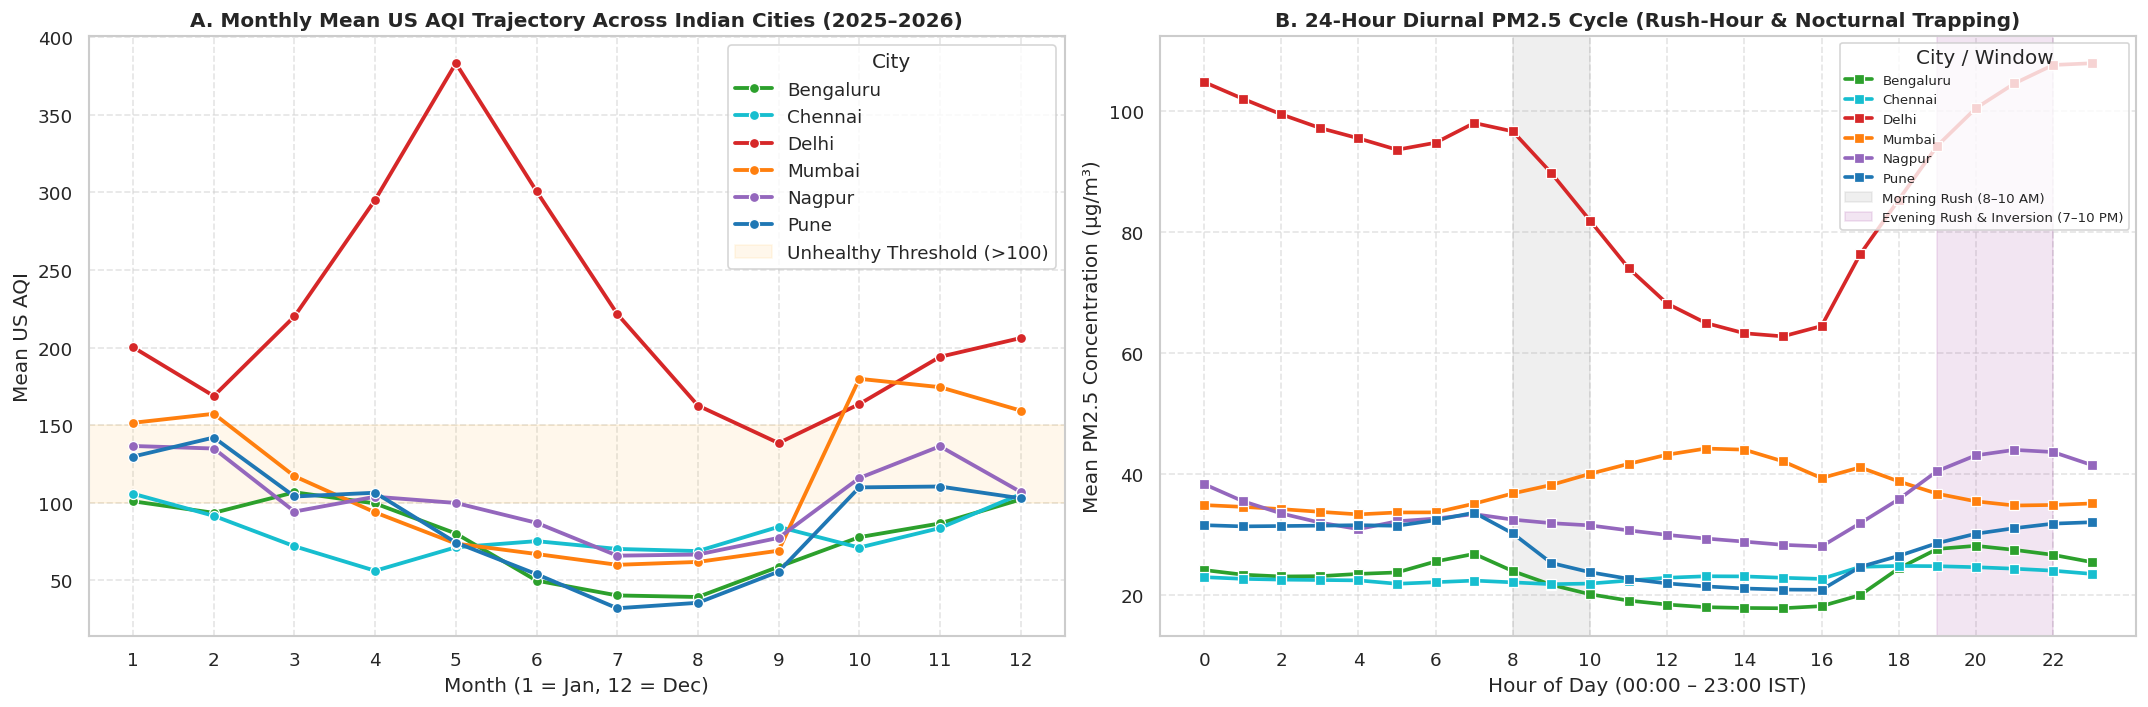

In [8]:
# Line Plots (Monthly Seasonal AQI Trend & 24-Hour Diurnal Pollution Curve)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Panel A: Monthly Mean US AQI Trajectory
monthly_aqi = df.groupby(['month', 'city'])['us_aqi'].mean().reset_index()
sns.lineplot(
    data=monthly_aqi, x='month', y='us_aqi', hue='city',
    palette=CITY_PALETTE, marker='o', linewidth=2.3, ax=axes[0]
)
axes[0].axhspan(100, 150, color='orange', alpha=0.08, label='Unhealthy Threshold (>100)')
axes[0].set_title('A. Monthly Mean US AQI Trajectory Across Indian Cities (2025–2026)')
axes[0].set_xlabel('Month (1 = Jan, 12 = Dec)')
axes[0].set_ylabel('Mean US AQI')
axes[0].set_xticks(range(1, 13))
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(title='City', loc='upper right')

# Panel B: 24-Hour Diurnal Cycle of PM2.5 (Traffic Rush-Hour & Boundary Layer Effect)
hourly_pm25 = df.groupby(['hour', 'city'])['pm2_5'].mean().reset_index()
sns.lineplot(
    data=hourly_pm25, x='hour', y='pm2_5', hue='city',
    palette=CITY_PALETTE, marker='s', linewidth=2.2, ax=axes[1]
)
axes[1].axvspan(8, 10, color='gray', alpha=0.12, label='Morning Rush (8–10 AM)')
axes[1].axvspan(19, 22, color='purple', alpha=0.10, label='Evening Rush & Inversion (7–10 PM)')
axes[1].set_title('B. 24-Hour Diurnal PM2.5 Cycle (Rush-Hour & Nocturnal Trapping)')
axes[1].set_xlabel('Hour of Day (00:00 – 23:00 IST)')
axes[1].set_ylabel('Mean PM2.5 Concentration (µg/m³)')
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(title='City / Window', loc='upper right', fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '01_lineplots_seasonal_diurnal.png'), bbox_inches='tight')
plt.show()

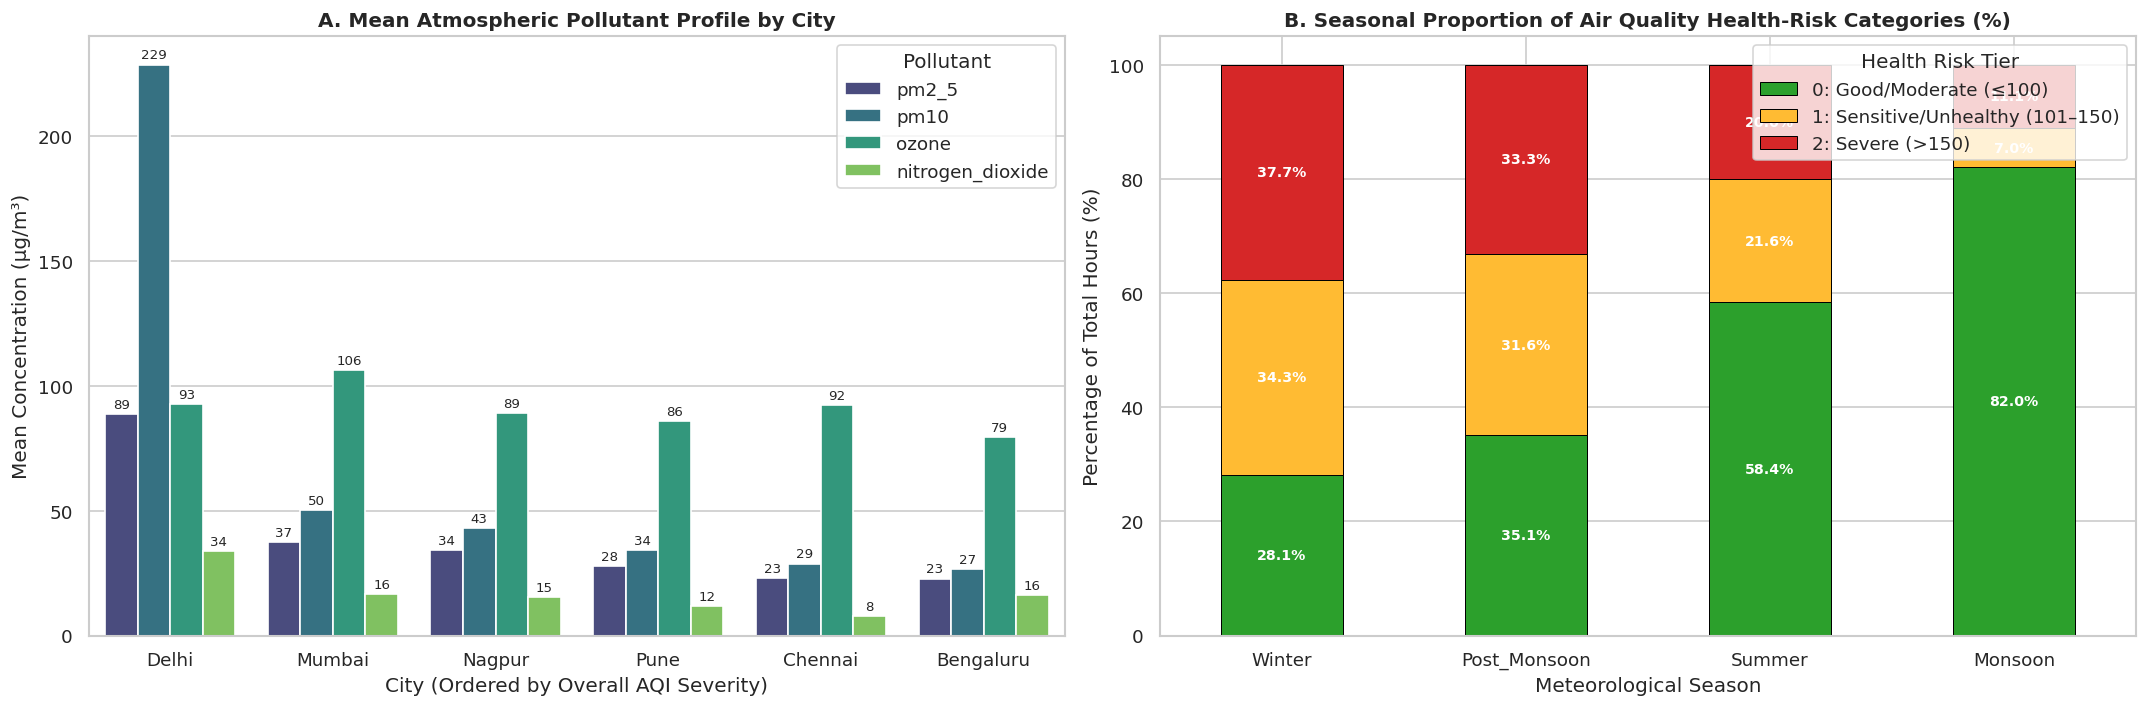

In [9]:
# Grouped Bar Plot (Pollutant Profiles) & Stacked Bar Plot (Seasonal Health Risk)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Panel A: Grouped Bar Plot of Mean Pollutants by City
city_pollutants = (
    df.groupby('city')[['pm2_5', 'pm10', 'ozone', 'nitrogen_dioxide']]
    .mean()
    .reindex(['Delhi', 'Mumbai', 'Nagpur', 'Pune', 'Chennai', 'Bengaluru'])
    .reset_index()
    .melt(id_vars='city', var_name='Pollutant', value_name='Concentration (µg/m³)')
)

sns.barplot(
    data=city_pollutants, x='city', y='Concentration (µg/m³)',
    hue='Pollutant', palette='viridis', ax=axes[0]
)
axes[0].set_title('A. Mean Atmospheric Pollutant Profile by City')
axes[0].set_xlabel('City (Ordered by Overall AQI Severity)')
axes[0].set_ylabel('Mean Concentration (µg/m³)')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.0f', fontsize=8, padding=2)

# Panel B: 100% Stacked Bar Chart of Health Risk Levels Across Seasons
season_order = ['Winter', 'Post_Monsoon', 'Summer', 'Monsoon']
season_risk = pd.crosstab(df['season'], df['risk_label'], normalize='index').reindex(season_order) * 100

season_risk.plot(
    kind='bar', stacked=True,
    color=['#2ca02c', '#ffbb33', '#d62728'],
    edgecolor='black', linewidth=0.6, ax=axes[1]
)
axes[1].set_title('B. Seasonal Proportion of Air Quality Health-Risk Categories (%)')
axes[1].set_xlabel('Meteorological Season')
axes[1].set_ylabel('Percentage of Total Hours (%)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Health Risk Tier', loc='upper right')

# Add percentage labels inside stacked bars
for c in axes[1].containers:
    axes[1].bar_label(c, fmt='%.1f%%', label_type='center', fontsize=8.5, color='white', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '02_barplots_city_season_risk.png'), bbox_inches='tight')
plt.show()

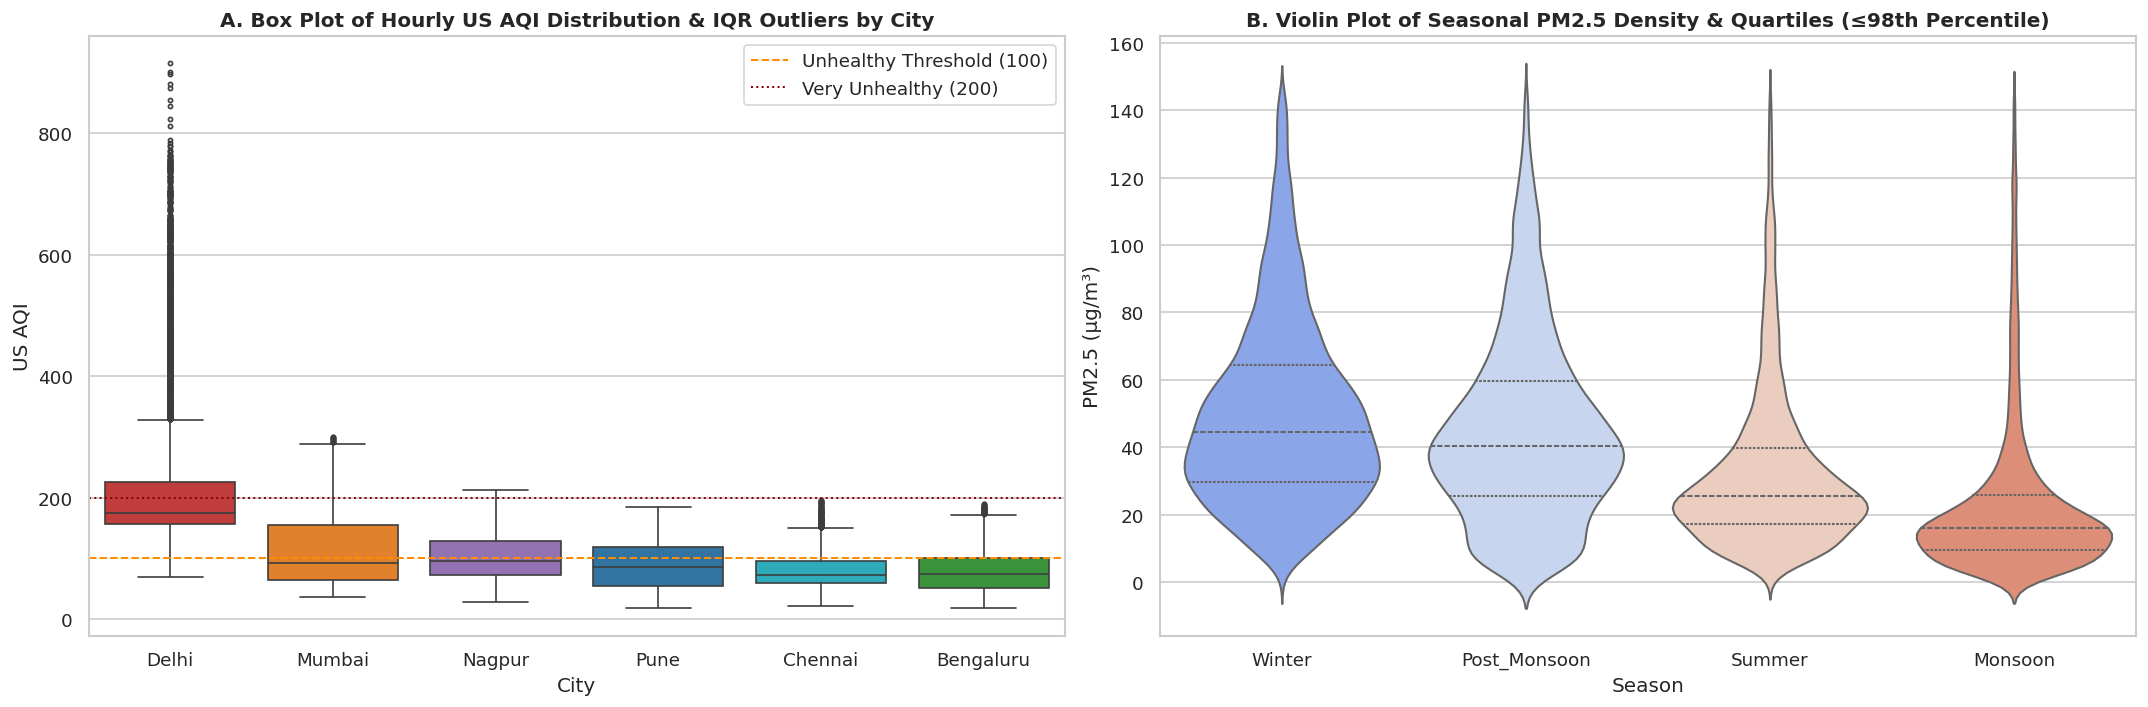

In [10]:
# Box Plot (US AQI Outlier Spread) & Violin Plot (Seasonal PM2.5 Density)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Panel A: Box Plot of US AQI across Cities (highlights extreme winter/festival outliers)
city_order = ['Delhi', 'Mumbai', 'Nagpur', 'Pune', 'Chennai', 'Bengaluru']
sns.boxplot(
    data=df, x='city', y='us_aqi', order=city_order,
    palette=CITY_PALETTE, fliersize=2.5, ax=axes[0]
)
axes[0].axhline(100, color='darkorange', linestyle='--', linewidth=1.2, label='Unhealthy Threshold (100)')
axes[0].axhline(200, color='darkred', linestyle=':', linewidth=1.2, label='Very Unhealthy (200)')
axes[0].set_title('A. Box Plot of Hourly US AQI Distribution & IQR Outliers by City')
axes[0].set_xlabel('City')
axes[0].set_ylabel('US AQI')
axes[0].legend(loc='upper right')

# Panel B: Violin Plot of PM2.5 (Capped at 98th percentile for clear kernel density visibility)
pm25_cap = df['pm2_5'].quantile(0.98)
sns.violinplot(
    data=df[df['pm2_5'] <= pm25_cap],
    x='season', y='pm2_5', order=['Winter', 'Post_Monsoon', 'Summer', 'Monsoon'],
    palette='coolwarm', inner='quartile', ax=axes[1]
)
axes[1].set_title('B. Violin Plot of Seasonal PM2.5 Density & Quartiles (≤98th Percentile)')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('PM2.5 (µg/m³)')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '03_boxplot_violinplot_distributions.png'), bbox_inches='tight')
plt.show()

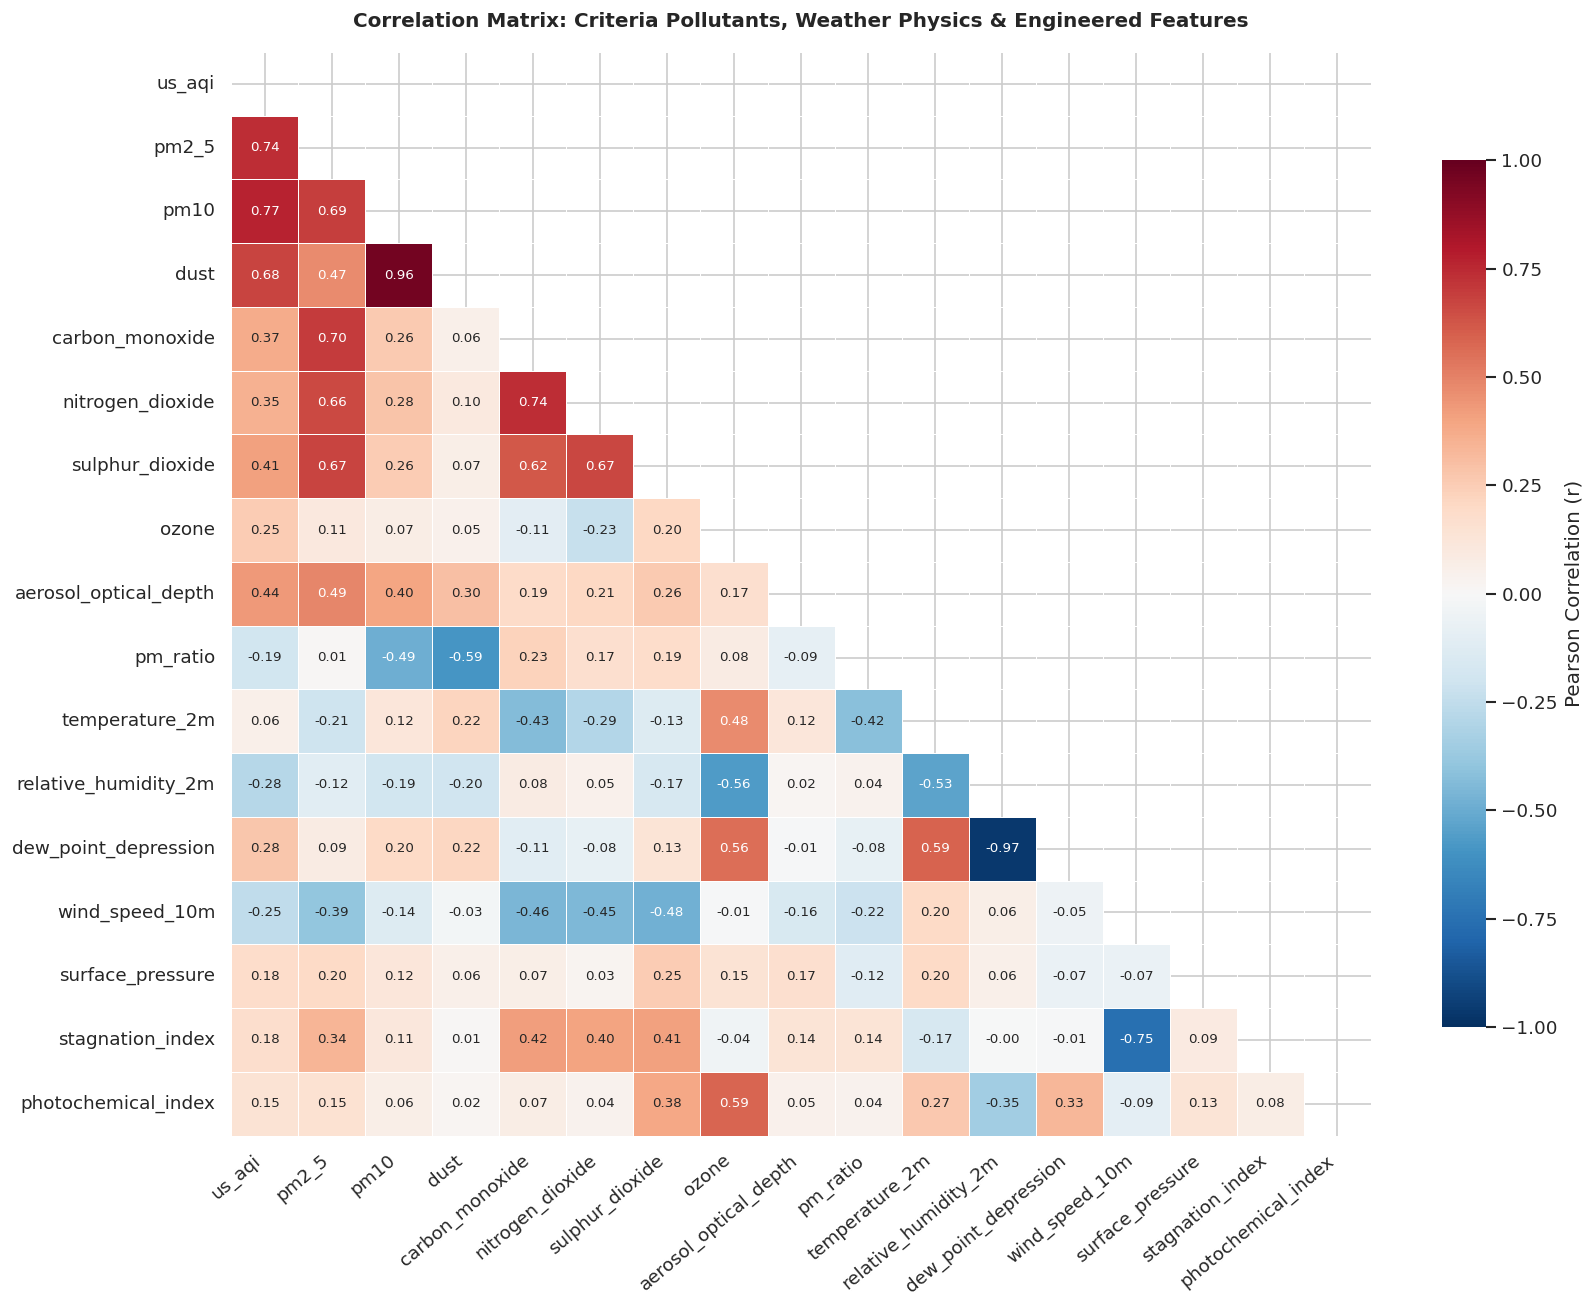

In [11]:
# Lower-Triangle Annotated Correlation Matrix Heatmap
corr_cols = [
    'us_aqi', 'pm2_5', 'pm10', 'dust', 'carbon_monoxide', 'nitrogen_dioxide',
    'sulphur_dioxide', 'ozone', 'aerosol_optical_depth', 'pm_ratio',
    'temperature_2m', 'relative_humidity_2m', 'dew_point_depression',
    'wind_speed_10m', 'surface_pressure', 'stagnation_index', 'photochemical_index'
]

corr_matrix = df[corr_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(14, 11))
sns.heatmap(
    corr_matrix, mask=mask, cmap='RdBu_r', vmin=-1, vmax=1, center=0,
    annot=True, fmt='.2f', annot_kws={'size': 8},
    linewidths=0.5, cbar_kws={'shrink': 0.8, 'label': 'Pearson Correlation (r)'}
)
plt.title('Correlation Matrix: Criteria Pollutants, Weather Physics & Engineered Features', pad=15)
plt.xticks(rotation=40, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '04_correlation_matrix_heatmap.png'), bbox_inches='tight')
plt.show()

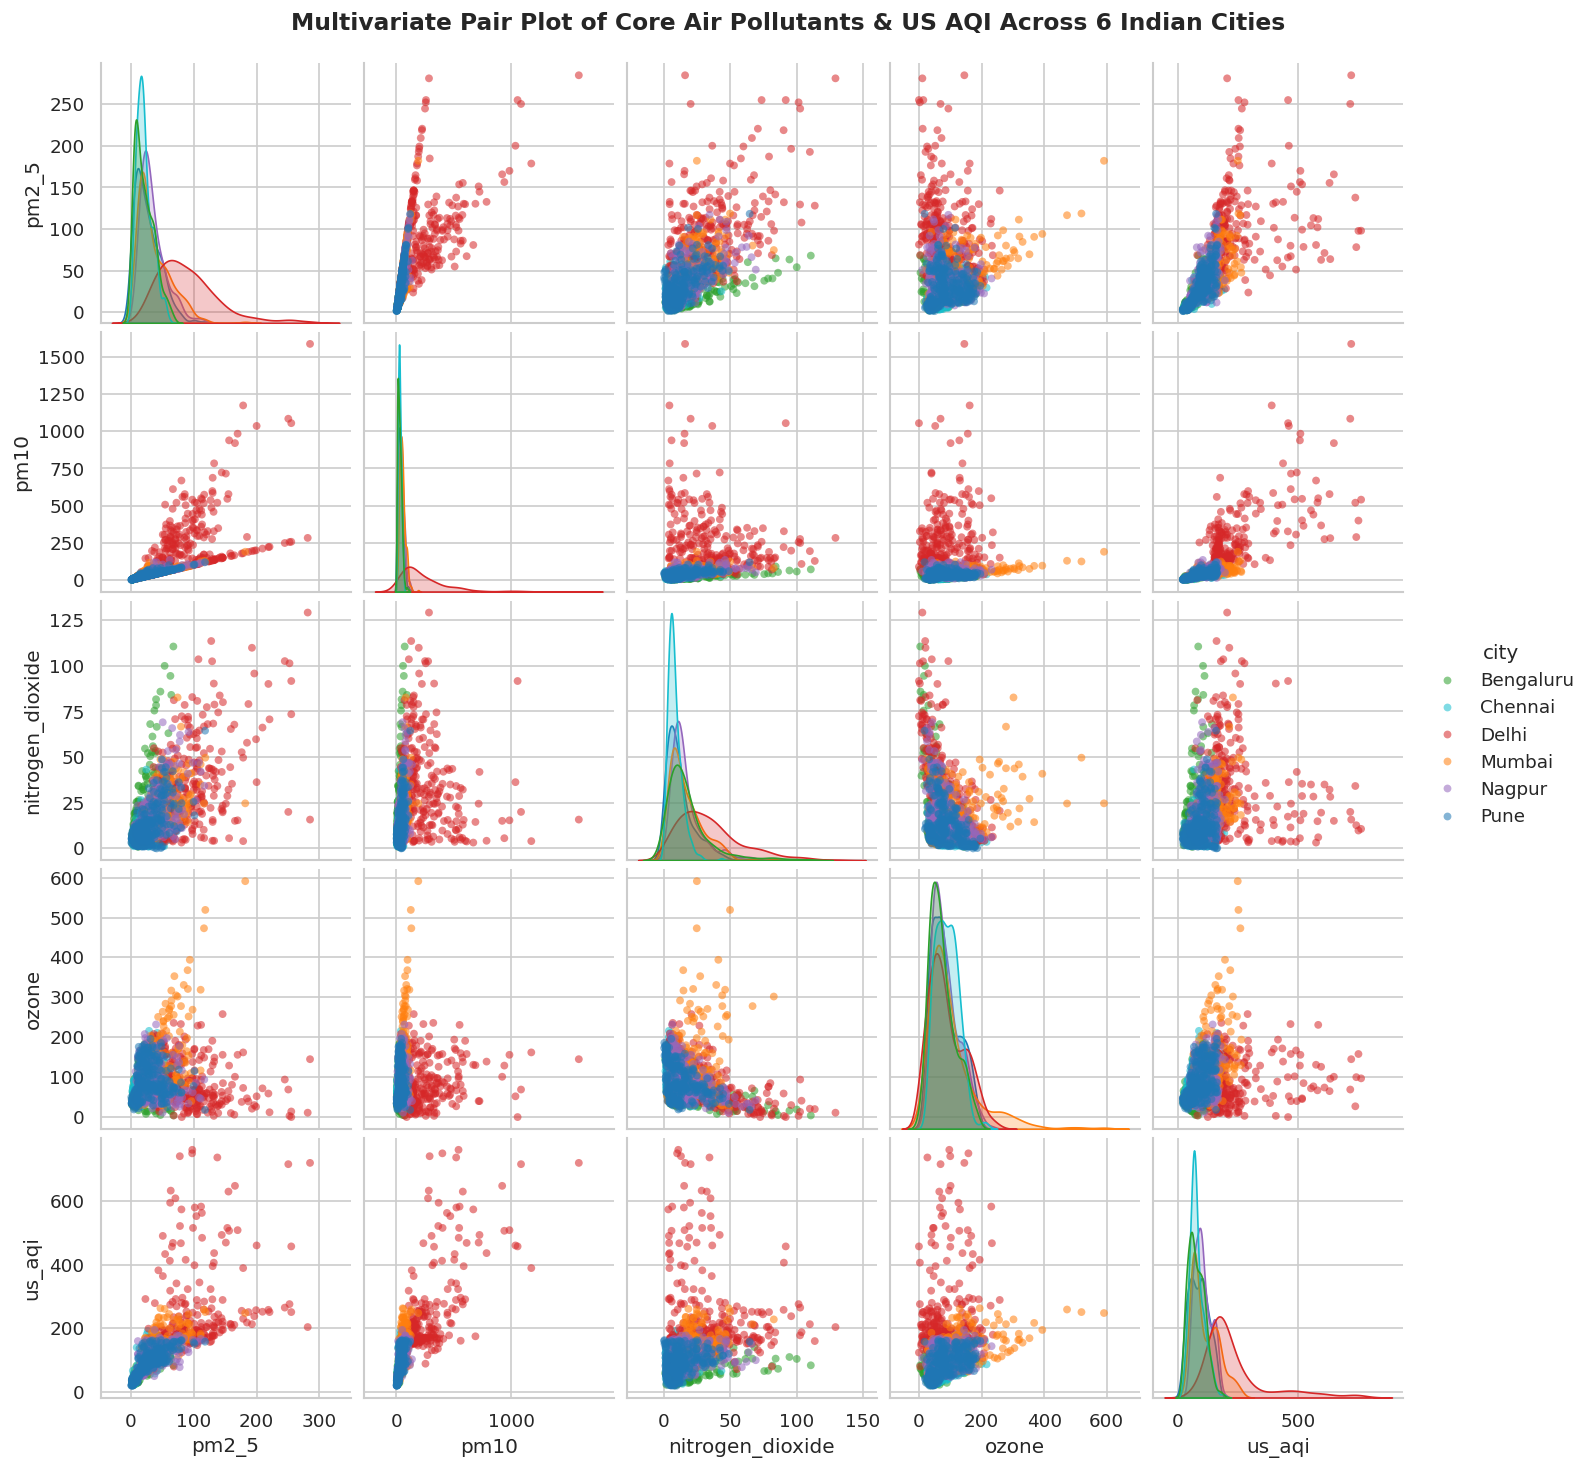

In [12]:
# Multivariate Pair Plot Colored by City (Stratified 1,800-Row Sample)
df_pair = (
    df.groupby('city', group_keys=False)
    .apply(lambda x: x.sample(n=300, random_state=42))
    .reset_index(drop=True)
)

pair_cols = ['pm2_5', 'pm10', 'nitrogen_dioxide', 'ozone', 'us_aqi']
pair_grid = sns.pairplot(
    df_pair,
    vars=pair_cols,
    hue='city',
    palette=CITY_PALETTE,
    diag_kind='kde',
    plot_kws={'alpha': 0.55, 's': 22, 'edgecolor': 'none'},
    height=2.4
)
pair_grid.fig.suptitle(
    'Multivariate Pair Plot of Core Air Pollutants & US AQI Across 6 Indian Cities',
    y=1.02, fontsize=14, fontweight='bold'
)
plt.savefig(os.path.join(FIG_DIR, '05_pairplot_multicity_pollutants.png'), bbox_inches='tight')
plt.show()

In [13]:
# Interactive Sunburst Chart (Region Zone -> City -> Season -> Health Risk)
sunburst_df = (
    df.groupby(['region_zone', 'city', 'season', 'risk_label'], as_index=False)
    .agg(
        hour_count=('us_aqi', 'count'),
        mean_aqi=('us_aqi', 'mean'),
        mean_pm25=('pm2_5', 'mean')
    )
)

fig_sunburst = px.sunburst(
    sunburst_df,
    path=['region_zone', 'city', 'season', 'risk_label'],
    values='hour_count',
    color='mean_aqi',
    color_continuous_scale='RdYlGn_r',
    range_color=[50, 250],
    hover_data={'mean_aqi': ':.1f', 'mean_pm25': ':.1f', 'hour_count': ':,'},
    title='Hierarchical Air Quality Breakdown: Climatic Zone → City → Season → Health Risk'
)

fig_sunburst.update_traces(
    textinfo='label+percent parent',
    insidetextorientation='radial'
)
fig_sunburst.update_layout(
    width=950,
    height=750,
    coloraxis_colorbar=dict(title='Mean US AQI')
)

# Save interactive HTML for viva demo
fig_sunburst.write_html(os.path.join(FIG_DIR, '06_interactive_sunburst.html'))
fig_sunburst.show()

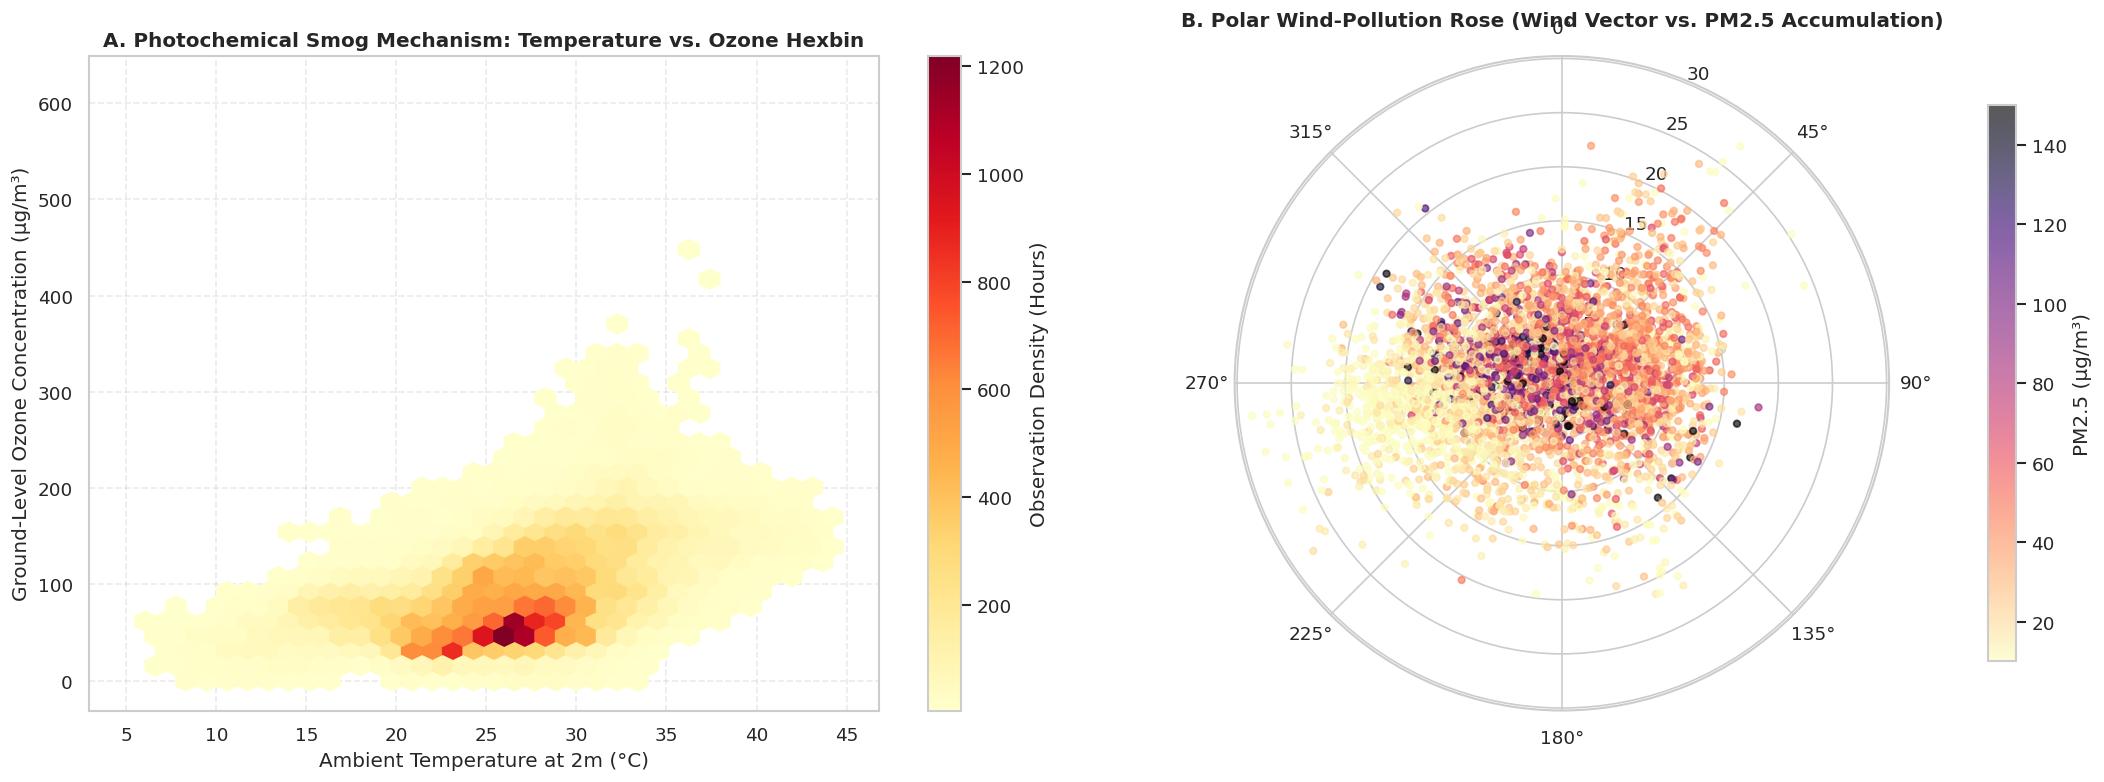

In [14]:
# Photochemical Smog Hexbin Density & Polar Wind-Pollution Rose
fig = plt.figure(figsize=(18, 6.5))

# Panel A: Hexbin Density Plot (Temperature vs. Ground-Level Ozone Formation)
ax1 = fig.add_subplot(1, 2, 1)
hb = ax1.hexbin(
    df['temperature_2m'], df['ozone'],
    gridsize=35, cmap='YlOrRd', mincnt=5
)
cb = fig.colorbar(hb, ax=ax1, label='Observation Density (Hours)')
ax1.set_title('A. Photochemical Smog Mechanism: Temperature vs. Ozone Hexbin')
ax1.set_xlabel('Ambient Temperature at 2m (°C)')
ax1.set_ylabel('Ground-Level Ozone Concentration (µg/m³)')
ax1.grid(True, linestyle='--', alpha=0.4)

# Panel B: Polar Wind-Pollution Rose (Wind Direction & Speed vs. Mean PM2.5)
ax2 = fig.add_subplot(1, 2, 2, projection='polar')
df_wind_sample = df.sample(n=4000, random_state=42)
theta = np.deg2rad(df_wind_sample['wind_direction_10m'])
r = df_wind_sample['wind_speed_10m']

sc = ax2.scatter(
    theta, r, c=df_wind_sample['pm2_5'],
    cmap='magma_r', alpha=0.65, s=16, vmin=10, vmax=150
)
ax2.set_theta_zero_location('N')
ax2.set_theta_direction(-1)
ax2.set_title('B. Polar Wind-Pollution Rose (Wind Vector vs. PM2.5 Accumulation)', pad=18)
cbar2 = plt.colorbar(sc, ax=ax2, pad=0.1, shrink=0.85)
cbar2.set_label('PM2.5 (µg/m³)')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '07_hexbin_and_wind_rose.png'), bbox_inches='tight')
plt.show()

In [15]:
# Interactive Geospatial Bubble Map of the 6 Monitored Indian Cities
geo_summary = (
    df.groupby(['city', 'region_zone', 'latitude', 'longitude'], as_index=False)
    .agg(
        mean_aqi=('us_aqi', 'mean'),
        max_aqi=('us_aqi', 'max'),
        mean_pm25=('pm2_5', 'mean'),
        mean_pm10=('pm10', 'mean'),
        unhealthy_pct=('high_health_risk', lambda x: x.mean() * 100)
    )
    .round(2)
)

fig_map = px.scatter_geo(
    geo_summary,
    lat='latitude',
    lon='longitude',
    text='city',
    size='mean_pm25',
    color='mean_aqi',
    color_continuous_scale='RdYlGn_r',
    size_max=40,
    hover_name='city',
    hover_data={
        'region_zone': True,
        'mean_aqi': True,
        'max_aqi': True,
        'mean_pm25': True,
        'unhealthy_pct': ':.1f'
    },
    title='Spatial Distribution of Annual Mean US AQI & PM2.5 Burden Across India (2025–2026)'
)

fig_map.update_geos(
    scope='asia',
    center=dict(lat=21.0, lon=78.5),
    projection_scale=4.2,
    showcountries=True,
    countrycolor='lightgray',
    showland=True,
    landcolor='#f8f9fa'
)
fig_map.update_traces(textposition='top center', textfont=dict(size=11, color='black'))
fig_map.update_layout(width=950, height=650, coloraxis_colorbar=dict(title='Mean US AQI'))

fig_map.write_html(os.path.join(FIG_DIR, '08_interactive_india_aqi_map.html'))
fig_map.show()

In [16]:
df.head()

,city,region_zone,latitude,longitude,time,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,...,wind_direction_10m_norm,shortwave_radiation_norm,pm_ratio_norm,dew_point_depression_norm,stagnation_index_norm,photochemical_index_norm,month_norm,hour_norm,day_of_week_norm,risk_label
0,Pune,West_Deccan,18.5204,73.8567,2025-11-10 00:00:00,44.9,44.8,964.0,37.1,23.4,...,0.707521,0.0,0.997522,0.170960,0.123593,0.0,0.909091,0.000000,0.0,0: Good/Moderate (≤100)
1,Pune,West_Deccan,18.5204,73.8567,2025-11-10 01:00:00,49.2,49.1,741.0,37.1,23.7,...,0.718663,0.0,0.997739,0.145199,0.173812,0.0,0.909091,0.043478,0.0,0: Good/Moderate (≤100)
2,Pune,West_Deccan,18.5204,73.8567,2025-11-10 02:00:00,52.5,52.4,562.0,36.4,23.9,...,0.523677,0.0,0.997881,0.131148,0.432066,0.0,0.909091,0.086957,0.0,0: Good/Moderate (≤100)
3,Pune,West_Deccan,18.5204,73.8567,2025-11-10 03:00:00,54.2,54.0,464.0,34.9,24.2,...,0.766017,0.0,0.995895,0.121780,0.317221,0.0,0.909091,0.130435,0.0,0: Good/Moderate (≤100)
4,Pune,West_Deccan,18.5204,73.8567,2025-11-10 04:00:00,54.1,53.9,411.0,32.7,24.4,...,0.891365,0.0,0.995887,0.093677,0.411185,0.0,0.909091,0.173913,0.0,0: Good/Moderate (≤100)


In [1]:
# Install Compatible NumPy & Trigger Auto-Restart if necessary
import sys
import os
import numpy as np
import pandas as pd

# Check if the active NumPy version is incompatible (>= 2.4)
major, minor = map(int, np.__version__.split('.')[:2])
if (major, minor) >= (2, 4):
    print(f"Current active NumPy version is {np.__version__} (Incompatible with Numba). Installing numpy<2.4...")
    !pip install -q "numpy<2.4" ydata-profiling
    print("\n*** RESTARTING SESSION TO APPLY CHANGES ***")
    print("Colab will disconnect and reconnect automatically in a few seconds. Please run this cell again once it reconnects!")
    import os
    os.kill(os.getpid(), 9)
else:
    print(f"Using compatible NumPy version: {np.__version__}")

    # Automatically reload 'df' if it was cleared from memory due to the session restart
    if 'df' not in globals():
        print("DataFrame 'df' not found in memory (due to session restart). Reloading dataset...")
        DATA_PATH = '/content/drive/MyDrive/Mini Project/dataset/aqi_2026.csv'
        if not os.path.exists(DATA_PATH):
            DATA_PATH = 'india_1yr_air_quality_full_2026.csv'
        df = pd.read_csv(DATA_PATH)
        print(f"Loaded dataset successfully: {df.shape[0]:,} rows x {df.shape[1]} columns")

    from ydata_profiling import ProfileReport

    # Profiling the UNSCALED data
    profile = ProfileReport(df, title="AQI 2026 - Profiling", minimal=True)
    profile.to_notebook_iframe()

    # Save the report to Google Drive
    report_dir = "/content/drive/MyDrive/Mini Project"
    os.makedirs(report_dir, exist_ok=True)
    profile.to_file(os.path.join(report_dir, "aqi_2026_report.html"))

Output hidden; open in https://colab.research.google.com to view.